# Perbaikan Citra Berwarna

---

### 1. Konsep Dasar

Perbaikan citra berwarna bertujuan untuk meningkatkan kualitas visual atau menyesuaikan representasi warna citra agar lebih informatif dan mudah diinterpretasi. Operasi ini dapat diaplikasikan pada berbagai ruang warna seperti **RGB**, **HSV**, atau **LAB**.

**Cakupan Teknik Utama:**
- **Koreksi Kontras & Kecerahan:** Penyesuaian rentang dinamis intensitas warna.
- **Peningkatan Kontras Adaptif:** Ekualisasi pencahayaan tanpa merusak tonal warna alami.
- **Pseudo Color:** Pemetaan intensitas citra monokromatik (*grayscale*) ke spektrum warna tertentu (*colormap*) untuk visualisasi data (misal: citra medis atau citra termal).

#### Karakteristik Ruang Warna:
- **RGB (Red, Green, Blue):** Model warna aditif berbasis perangkat display; informasi warna dan pencahayaan bercampur pada setiap kanal.
- **HSV (Hue, Saturation, Value):** Memisahkan corak warna (*Hue*), kejenuhan (*Saturation*), dan intensitas cahaya (*Value*).
- **LAB:** Ruang warna berbasis persepsi penglihatan manusia. Kanal **L** (*Luminance*) memisahkan kecerahan secara independen dari komponen kromatik **A** (hijau-merah) dan **B** (biru-kuning).

### 2. Ringkasan Operasi Perbaikan Warna

| Teknik | Ruang Warna | Mekanisme Kerja |
| :--- | :--- | :--- |
| **Penyesuaian Skala Linier** | RGB | $g(x, y) = \alpha \cdot f(x, y) + \beta$ diterapkan seragam ke seluruh kanal |
| **Histogram Equalization** | HSV | Diterapkan hanya pada kanal **V** agar tonalitas warna (*H* dan *S*) tidak terdistorsi |
| **CLAHE** | LAB | Kontras adaptif berbasis ubin (*tiles*) pada kanal **L** untuk mencegah amplifikasi *noise* |
| **Pseudo Color** | Grayscale $\rightarrow$ RGB | Mentranslasikan skala intensitas 0–255 ke spektrum palet warna buatan |

### 3. Implementasi Python

#### Persiapan Lingkungan & Citra Sampel
Cell ini memuat pustaka yang dibutuhkan serta mengunduh citra uji jika belum tersedia secara lokal.

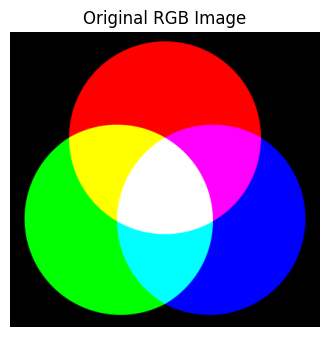

In [ ]:
!pip install cairosvg

import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import urllib.request
import cairosvg

opener = urllib.request.build_opener()
opener.addheaders = [('User-Agent', 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)')]
urllib.request.install_opener(opener)

svg_file = 'color_image.svg'
png_file = 'color_image.png'

# Unduh berkas SVG jika belum ada
if not os.path.exists(svg_file):
    url = 'https://upload.wikimedia.org/wikipedia/commons/e/e0/Synthese%2B.svg?utm_source=commons.wikimedia.org&utm_campaign=index&utm_content=original'
    urllib.request.urlretrieve(url, svg_file)

# Konversi SVG ke PNG menggunakan cairosvg
cairosvg.svg2png(url=svg_file, write_to=png_file)

# Baca hasil konversi PNG dengan OpenCV
img_bgr = cv2.imread(png_file)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(4, 4))
plt.imshow(img_rgb)
plt.title('Original RGB Image')
plt.axis('off')
plt.show()

#### a. Koreksi Kontras dan Kecerahan di Ruang RGB
Fungsi `cv2.convertScaleAbs` melakukan transformasi linier dengan parameter $\alpha$ (faktor kontras) dan $\beta$ (faktor kecerahan).

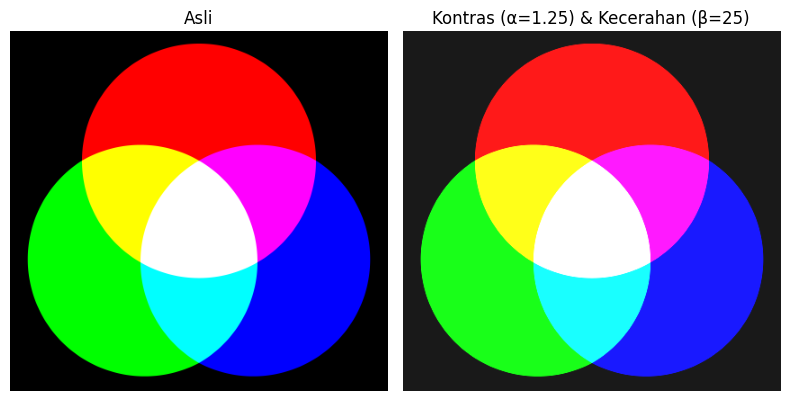

In [12]:
alpha = 1.25  # Kontras (>1 meningkatkan kontras)
beta = 25     # Kecerahan (offset intensitas)

adjusted_rgb = cv2.convertScaleAbs(img_rgb, alpha=alpha, beta=beta)

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title('Asli')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(adjusted_rgb)
plt.title(f'Kontras (α={alpha}) & Kecerahan (β={beta})')
plt.axis('off')

plt.tight_layout()
plt.show()

#### b. Histogram Equalization pada Kanal V (HSV)
Ekualisasi diterapkan secara eksklusif pada kanal *Value* ($V$) untuk meningkatkan rentang dinamis intensitas tanpa mengubah rona (*Hue*) atau saturasi warna.

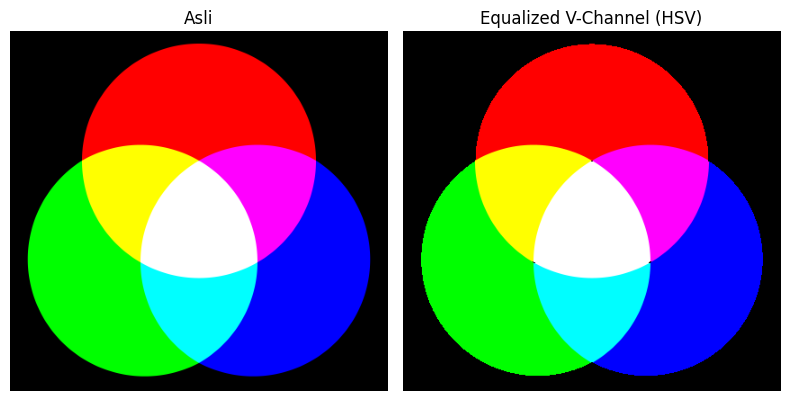

In [13]:
hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
h, s, v = cv2.split(hsv)

# Ekualisasi histogram kanal V
v_eq = cv2.equalizeHist(v)
hsv_eq = cv2.merge((h, s, v_eq))
img_hsv_eq = cv2.cvtColor(hsv_eq, cv2.COLOR_HSV2RGB)

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title('Asli')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_hsv_eq)
plt.title('Equalized V-Channel (HSV)')
plt.axis('off')

plt.tight_layout()
plt.show()

#### c. CLAHE pada Kanal L (LAB)
*Contrast Limited Adaptive Histogram Equalization* (CLAHE) mencegah amplifikasi derau berlebih pada area citra yang relatif homogen dengan membatasi nilai *clip limit*.

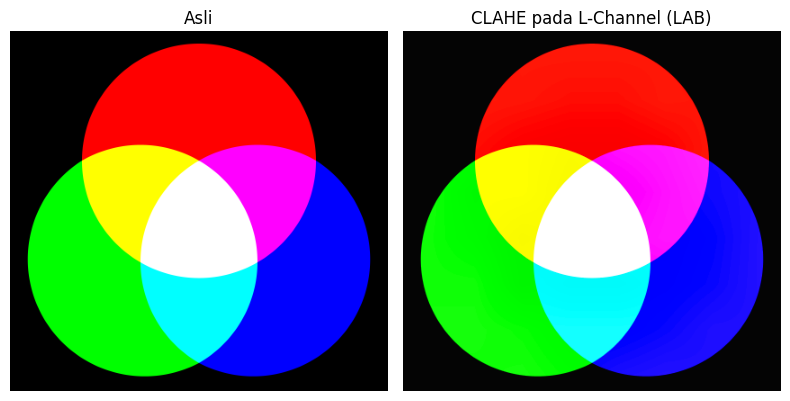

In [14]:
lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
l, a, b = cv2.split(lab)

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
l_clahe = clahe.apply(l)
lab_clahe = cv2.merge((l_clahe, a, b))
img_clahe = cv2.cvtColor(lab_clahe, cv2.COLOR_LAB2RGB)

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title('Asli')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_clahe)
plt.title('CLAHE pada L-Channel (LAB)')
plt.axis('off')

plt.tight_layout()
plt.show()

#### d. Pseudo Color (False Color Mapping)
Mengonversi citra monokromatik menjadi representasi warna menggunakan palet (*colormap*) untuk memperjelas gradasi intensitas.

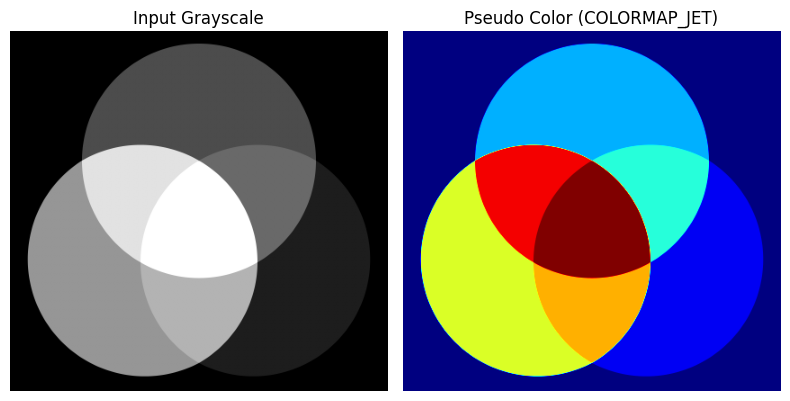

In [15]:
gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

# Pemetaan pseudo color menggunakan preset COLORMAP_JET
pseudo_jet = cv2.applyColorMap(gray, cv2.COLORMAP_JET)
pseudo_jet_rgb = cv2.cvtColor(pseudo_jet, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(gray, cmap='gray')
plt.title('Input Grayscale')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(pseudo_jet_rgb)
plt.title('Pseudo Color (COLORMAP_JET)')
plt.axis('off')

plt.tight_layout()
plt.show()

### 4. Kesimpulan

- **Kemandirian Pencahayaan:** Memisahkan komponen intensitas cahaya (*L* pada LAB atau *V* pada HSV) dari komponen kromatik memungkinkan peningkatan kontras tanpa menimbulkan perubahan corak (*color shifting*).
- **Preservasi Homogenitas:** CLAHE pada kanal *L* menghasilkan kontras yang lebih seimbang dibandingkan ekualisasi global konvensional.
- **Kegunaan Pseudo Color:** Memetakan rentang intensitas monokromatik ke palet warna spektral efektif membantu mata manusia membedakan variasi densitas kecil pada citra diagnostik dan termografi.